In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import finsler_learning.komatsuna_pipeline as sp
from finsler_learning.komatsuna_pipeline import *
import finsler_learning as fl
import json
from pathlib import Path
from finsler_learning.komatsuna_pipeline.komatsuna_utils import KomatsunaPipelineConfig
import pandas as pd

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from finsler_learning.komatsuna_pipeline.komatsuna_utils import *

from finsler_learning.base_extrapolation import (
    ExtrapolationEvalRiemannConfig,
    ExtrapolationEvalFinslerConfig,
    extrapolation_evaluation,
)
from finsler_learning.base_quality_evaluation import evaluate_extrapolated_framework
from finsler_learning.komatsuna_pipeline.komatsuna_interpolation import (
    get_randers_metric_trained,
)
from finsler_learning.base_extrapolation import *

from geodesic_toolbox.utils import (
    sample_cometric_normal,
    sample_cone_VMF,
)

In [3]:
import torch
from pathlib import Path
from torch import Tensor
import matplotlib.pyplot as plt
from torchvision.io import read_image
import numpy as np
import tqdm
from torchmetrics import MeanAbsolutePercentageError

from geodesic_toolbox import (
    IdentityCoMetric,
)

from finsler_learning.logger import setup_logger
from finsler_learning.models import VAE

from finsler_learning.base_geodesic_evaluation import (
    GeodesicEvalRiemannConfig,
    GeodesicSolverParams,
)
from finsler_learning.base_quality_evaluation import (
    evaluate_dataloaders,
    eval_ae_model,
)
from finsler_learning.komatsuna_pipeline.komatsuna_utils import *
from finsler_learning.komatsuna_pipeline.komatsuna_vae import train_vae
from finsler_learning.komatsuna_pipeline.komatsuna_nnunet import (
    get_model_regressor,
    get_vae_komatsuna_dataloaders,
)
from finsler_learning.komatsuna_pipeline.komatsuna_randers_training import (
    train_randers,
)
from finsler_learning.komatsuna_pipeline.komatsuna_interpolation import evaluate_monotonicity
from finsler_learning.komatsuna_pipeline.komatsuna_extrapolation import (
    evaluate_extrapolation,
)
from finsler_learning.komatsuna_pipeline.komatsuna_vae_stochastic import (
    train_vae_log_var_decoder_branch,
)
from finsler_learning.dataset import KOMATSUNADataset
from finsler_learning.komatsuna_pipeline.komatsuna_nnunet import (
    nnunet_pipeline,
    get_model_regressor,
)
from finsler_learning.komatsuna_pipeline.komatsuna_utils import KomatsunaPipelineConfig
import json
from einops import rearrange

In [4]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11")
with open(base_path / "komatsuna_pipeline_config.json", "r") as f:
    config = json.load(f)
config = KomatsunaPipelineConfig(**config)
config.export_path = Path(config.export_path)
config.device = torch.device(config.device)

config.device = torch.device("cpu")
latent_dim = config.latent_dim
export_path = config.export_path
device = config.device
batch_size = config.b_size_evaluation
alpha = config.alpha
ema_moment = config.ema_moment
eta = config.eta
n_pts = config.n_pts
k = config.n_neighbors
omega_strength = config.omega_strength
use_dummy_accuracy = config.use_dummy_accuracy
config

KomatsunaPipelineConfig(n_epochs_vae=1000, b_size_vae=128, lr_vae=5e-05, wd_vae=0.0, beta=1.0, lbda=1.0, lpip_weight=0.0, l1_weight=0.1, n_epochs_nnunet=100, n_neighbors=16, margin=0, n_epochs_randers=50, b_size_randers=128, use_dummy_accuracy=False, lr_randers=0.01, wd_randers=1e-06, omega_strength=0.9, b_size_evaluation=32, eta=0.999, alpha=5.0, ema_moment=0.9, n_pts=25, skip_nnunet=True, skip_vae=True, skip_randers=True, eval_interpolation=True, eval_extrapolation=True, export_path=PosixPath('/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11'), latent_dim=64, K_cometric=None, device=device(type='cpu'), eval_quality_interpolation=True, eval_quality_extrapolation=True, eval_regressor=False, no_symmetric=False, no_randers=False)

In [5]:
model = get_models(latent_dim=latent_dim)
dtype = next(model.parameters()).dtype
try_load_pretrained_models(export_path, model)
model = model.to(device)
model.eval()

regressor = get_model_regressor(
    config.export_path, config.device, n_epochs=config.n_epochs_nnunet
)

dl_config = DatasetConfig(
    batch_size=batch_size,
)

komatsuna_trainloader, komatsuna_test_loader = get_komatsuna_dataloaders(
    dl_config,
    export_path=config.export_path,
)

komatsuna_trainloader_vae, _ = get_vae_komatsuna_dataloaders(
    dataset_config=dl_config,
    latent_dim=latent_dim,
    device=device,
    export_path=export_path,
)


LOGGER.info(f"Number of training samples: {len(komatsuna_trainloader.dataset)}")
LOGGER.info(f"Number of test samples: {len(komatsuna_test_loader.dataset)}")

encoder = model.encoder.to(device)
decoder = model.decoder.to(device)
encoder.eval()
decoder.eval()

common_params = {
    "latent_dim": latent_dim,
    "dataloader_train": komatsuna_trainloader,
    "dataloader_test": komatsuna_test_loader,
    "encoder": encoder,
    "decoder": decoder,
    "regressor": regressor,
    "device": device,
    "reference_dataloader_train": komatsuna_trainloader_vae,
    "alpha": alpha,
    "moving_avg_momentum": ema_moment,
    "T": n_pts,
}

perform_everything_on_device=True is only supported for cuda devices! Setting this to False


In [6]:
def embed_dataset(dataloader, encoder, device):
    """
    Embed the dataset using the encoder and return the latent representations.
    """
    mu, logvar = [], []
    with torch.no_grad():
        for x, _ in tqdm(dataloader, desc="Embedding dataset"):
            x = x.to(device)
            mu_batch, logvar_batch = encoder(x)
            mu.append(mu_batch.cpu())
            logvar.append(logvar_batch.cpu())
    mu = torch.cat(mu, dim=0)
    logvar = torch.cat(logvar, dim=0)
    return mu, logvar


z_train, logvar_train = embed_dataset(komatsuna_trainloader, encoder, device)
z_test, logvar_test = embed_dataset(komatsuna_test_loader, encoder, device)

Embedding dataset: 100%|██████████| 6/6 [00:04<00:00,  1.23it/s]


In [7]:
res_acc = {}
for cometric_type in VALID_COMETRIC_TYPES.keys():
    if "biased" in cometric_type:
        continue
    print(f"Evaluating cometric type: {cometric_type}")
    cometric = get_cometric(
        latent_dim=latent_dim,
        export_path=export_path,
        k=k,
        batch_size=batch_size,
        cometric_type=cometric_type,
        device=device,
    ).to(dtype)
    randers_metric = get_randers_metric_trained(
        latent_dim=latent_dim,
        cometric=cometric,
        export_path=export_path,
        beta=omega_strength,
        use_dummy_accuracy=use_dummy_accuracy,
        device=device,
        cometric_type=cometric_type,
    ).to(dtype)

    J_omega = PullBackCometric(randers_metric.omega).jacobian(z_test)
    J_norm = torch.linalg.norm(J_omega, dim=(-2, -1)).squeeze().detach().cpu()
    curl_tensor_test = J_omega - J_omega.transpose(-1, -2)
    curl_test = torch.linalg.norm(curl_tensor_test, dim=(-2, -1)).squeeze().detach().cpu()
    relative_curl = curl_test / J_norm

    acc_train = randers_metric.omega.amplitude(z_train).squeeze().detach().cpu()
    acc_test = randers_metric.omega.amplitude(z_test).squeeze().detach().cpu()
    res_acc[cometric_type] = {
        "train_amplitude": acc_train,
        "test_amplitude": acc_test,
        "test_curl": curl_test,
        "test_relative_curl": relative_curl,
    }

Evaluating cometric type: euclidean


Evaluating cometric type: land_rbf


Evaluating cometric type: land


Evaluating cometric type: cov_centroids


Evaluating cometric type: pullback_centroids


In [8]:
frames = []
for cometric_type, res in res_acc.items():
    new_df = pd.DataFrame(
        {
            "test_amplitude": res["test_amplitude"].numpy(),
            "test_curl": res["test_curl"].numpy(),
            "test_relative_curl": res["test_relative_curl"].numpy(),
        }
    )
    new_df["cometric_type"] = cometric_type
    frames.append(new_df)
df_acc = pd.concat(frames, ignore_index=True)

/tmp/ipykernel_2525579/2857602391.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_2525579/2857602391.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


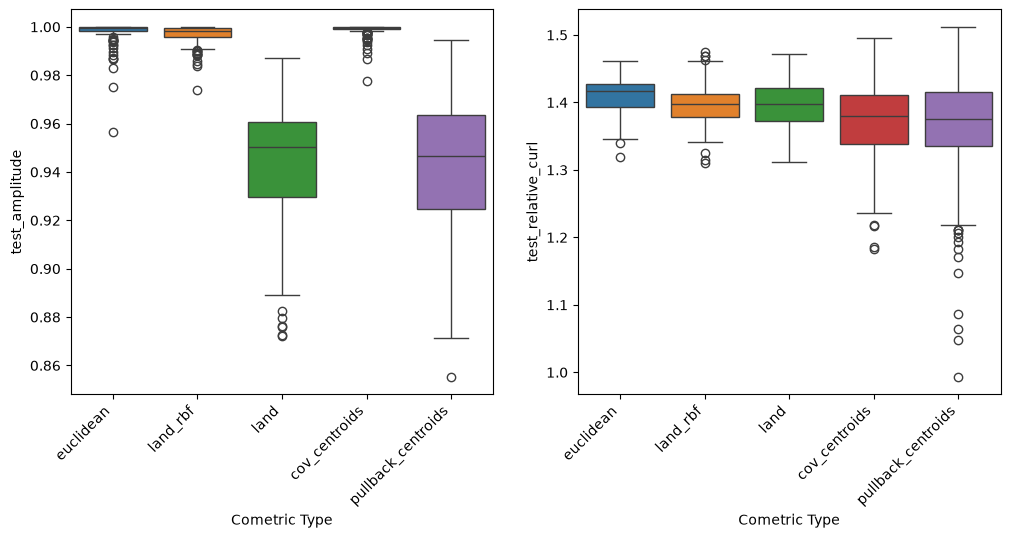

In [9]:
%matplotlib inline
fig,axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(
    data=df_acc,
    x="cometric_type",
    y="test_amplitude",
    hue="cometric_type",
    ax=axes[0]
)
sns.boxplot(
# sns.barplot(
    data=df_acc,
    x="cometric_type",
    # y="test_curl",
    y="test_relative_curl",
    hue="cometric_type",
    ax=axes[1]
)
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_xlabel("Cometric Type")
    

In [10]:
# Get all mean and std by cometric type
df_acc.groupby("cometric_type").agg(
    mean_test_amplitude=("test_amplitude", "mean"),
    std_test_amplitude=("test_amplitude", "std"),
    mean_test_curl=("test_curl", "mean"),
    std_test_curl=("test_curl", "std"),
    mean_test_relative_curl=("test_relative_curl", "mean"),
    std_test_relative_curl=("test_relative_curl", "std"),
)

,mean_test_amplitude,std_test_amplitude,mean_test_curl,std_test_curl,mean_test_relative_curl,std_test_relative_curl
cometric_type,,,,,,
cov_centroids,0.998908,0.002441,0.619232,3.893195,1.371979,0.056012
euclidean,0.998182,0.004461,0.194443,0.069888,1.410826,0.023626
land,0.944505,0.024876,0.031302,0.010861,1.395786,0.034427
land_rbf,0.996905,0.003714,0.140539,0.049531,1.397255,0.028771
pullback_centroids,0.942893,0.027614,2.620004,4.416822,1.360527,0.083302


Cometric type: euclidean
Train amplitude = 0.9977 ± 0.0062
Test amplitude = 0.9982 ± 0.0045


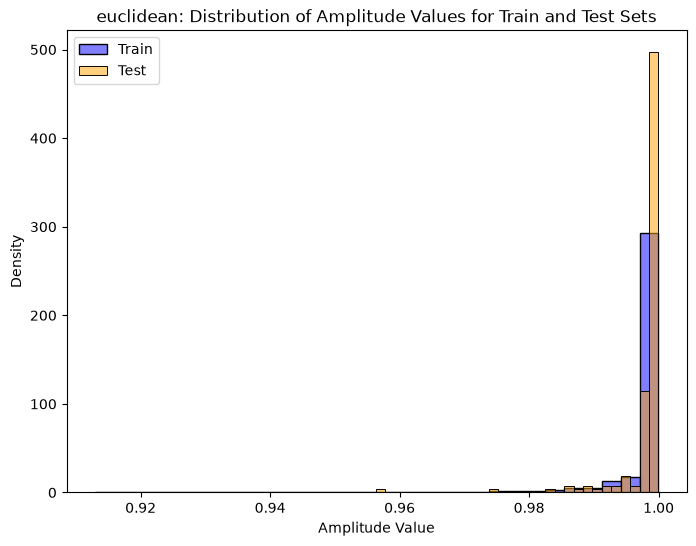

Cometric type: land_rbf
Train amplitude = 0.9962 ± 0.0067
Test amplitude = 0.9969 ± 0.0037


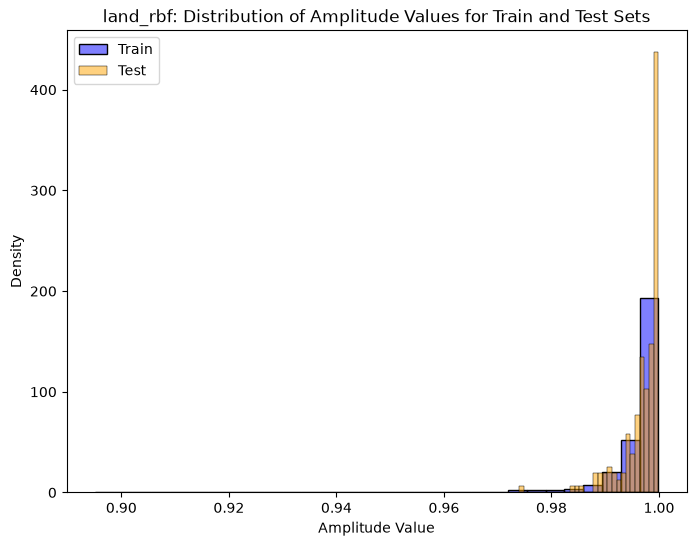

Cometric type: land
Train amplitude = 0.9469 ± 0.0260
Test amplitude = 0.9445 ± 0.0249


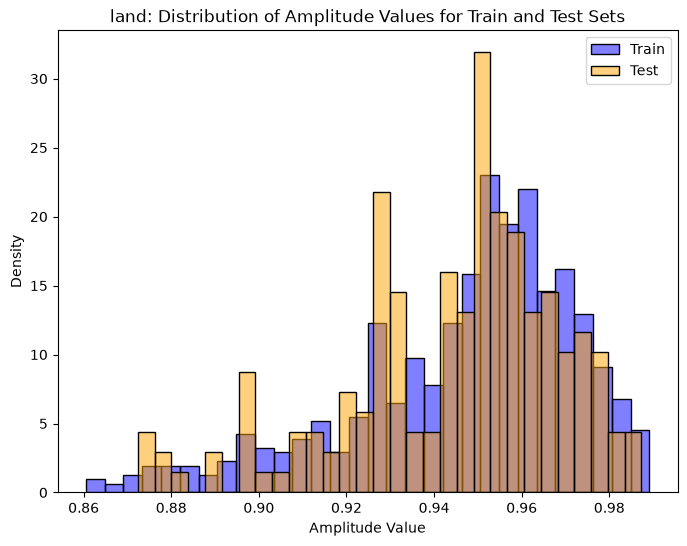

Cometric type: cov_centroids
Train amplitude = 0.9985 ± 0.0050
Test amplitude = 0.9989 ± 0.0024


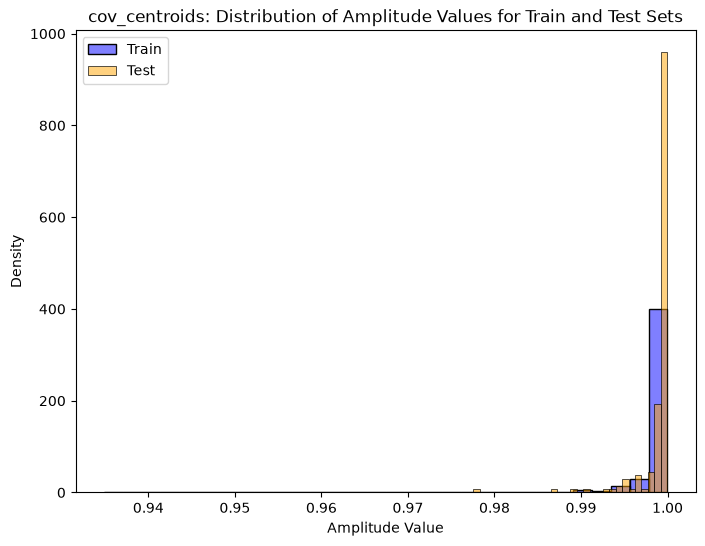

Cometric type: pullback_centroids
Train amplitude = 0.9447 ± 0.0289
Test amplitude = 0.9429 ± 0.0276


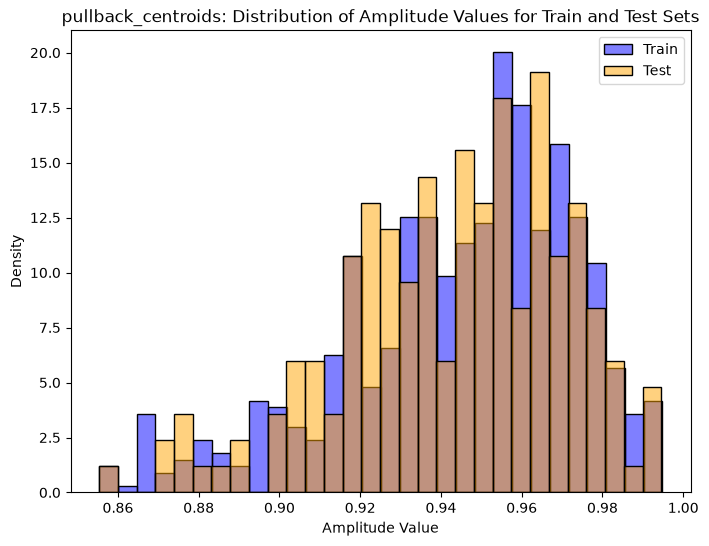

In [11]:
for cometric_type, res_dict in res_acc.items():
    print(f"Cometric type: {cometric_type}")
    print(
        f"Train amplitude = {res_dict['train_amplitude'].mean().item():.4f} ± {res_dict['train_amplitude'].std().item():.4f}"
    )
    print(
        f"Test amplitude = {res_dict['test_amplitude'].mean().item():.4f} ± {res_dict['test_amplitude'].std().item():.4f}"
    )
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.histplot(
        res_dict['train_amplitude'].numpy(),
        bins=30,
        color="blue",
        alpha=0.5,
        label="Train",
        stat="density",
    )
    sns.histplot(
        res_dict['test_amplitude'].numpy(),
        bins=30,
        color="orange",
        alpha=0.5,
        label="Test",
        stat="density",
    )
    # ax.set_xlim([0, 1])
    ax.set_title(f"{cometric_type}: Distribution of Amplitude Values for Train and Test Sets")
    ax.set_xlabel("Amplitude Value")
    ax.set_ylabel("Density")
    ax.legend()
    plt.show()